# MP4 — Exploratory Data Analysis: Readmisi Dini Diabetes
Jalankan **MP2 terlebih dahulu** pada ROOT yang sama. Notebook ini memeriksa checksum data agar indeks split tidak digunakan pada file berbeda. Analisis memakai train dan cleaner fit train saja. Jangan memakai hasil EDA ini untuk menyesuaikan model setelah melihat test; bila mengubah model, siapkan evaluasi independen baru.

Pertanyaan: **Q1** proporsi menurut usia; **Q2** hubungan riwayat rawat inap; **Q3** perbedaan distribusi lama rawat. Grafik dan tabel dihasilkan otomatis. Jawaban/interpretasi akhir wajib mahasiswa tulis sendiri.


## Sebelum menjalankan
Gunakan hasil MP2 yang sudah berhasil, pada folder `MyDrive/MP2_MP4_Diabetes/mp2`. Tidak perlu menjalankan ulang MP2. Pilih **Run all**. Sesi sehat yang telah menjalankan MP2 boleh digunakan langsung.

Notebook ini memakai pemeriksaan lingkungan yang sama dengan MP2 terbaru, tanpa memaksa penggantian NumPy/SciPy. Jika sesi pernah menjalankan sel instalasi versi lama dan muncul konflik impor, simpan pekerjaan lalu pilih **Runtime → Disconnect and delete runtime**, sambungkan kembali, dan jalankan notebook ini. File Google Drive tetap tersimpan.

Dataset dibaca langsung dari folder ETS/Dataset yang telah ditentukan. Analisis menggunakan `eda_train_clean.parquet` hasil MP2 (cleaner fit train saja); tidak memuat ulang model joblib. Grafik, tabel, dan poster disimpan di `MyDrive/MP2_MP4_Diabetes/mp4`.


In [ ]:
#@title Periksa lingkungan Colab (tanpa mengganti NumPy/SciPy bawaan)
import os, sys, subprocess, importlib, importlib.util, importlib.metadata, io, inspect
# PENTING: setelah notebook versi lama, gunakan Disconnect and delete runtime sekali.
# Restart session saja tidak mengembalikan paket yang sudah diganti di disk.
# Jangan melakukan pip install/upgrade NumPy, pandas, SciPy, sklearn di notebook ini.
if importlib.util.find_spec('pyarrow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           '--only-binary=:all:', '--no-deps', 'pyarrow'])
try:
    import numpy as np
    import numpy.char
    import pandas as pd
    import scipy
    from scipy import stats, sparse
    import sklearn
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
    from sklearn.tree import DecisionTreeClassifier
    import matplotlib
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pyarrow
    import joblib
    # Deteksi paket yang diganti di disk setelah diimpor ke runtime.
    for package, module in [('numpy',np),('pandas',pd),('scipy',scipy),('scikit-learn',sklearn)]:
        if module.__version__ != importlib.metadata.version(package):
            raise RuntimeError(f'{package}: versi memori berbeda dari versi instalasi')
    assert np.char.add(np.array(['uji']), np.array(['_ok']))[0] == 'uji_ok'
    assert np.isfinite(stats.norm.cdf(0))
    assert sparse.csr_matrix([[1.,0.],[0.,1.]]).shape == (2,2)
    assert 'sparse_output' in inspect.signature(OneHotEncoder).parameters
    _X=np.array([[0,1],[1,0],[0,2],[2,0]],dtype=float)
    _y=np.array([0,1,0,1])
    assert len(DecisionTreeClassifier(random_state=42).fit(_X,_y).predict(_X))==4
    _df=pd.DataFrame({'uji':[1,2]})
    assert pd.read_parquet(io.BytesIO(_df.to_parquet(index=False))).equals(_df)
    _fig,_ax=plt.subplots();_ax.plot([0,1],[0,1]);_buf=io.BytesIO()
    _fig.savefig(_buf,format='png');plt.close(_fig)
    assert len(_buf.getvalue())>0
except Exception as exc:
    raise RuntimeError(
        'Lingkungan Python belum sehat. Pada Colab pilih Runtime > Disconnect and delete runtime '
        '(Putuskan dan hapus runtime), sambungkan kembali, lalu Run all notebook INI. '
        'Jangan jalankan sel pip dari versi lama. Data pada Google Drive tetap tersimpan. '
        f'Detail: {type(exc).__name__}: {exc}'
    ) from exc
print('PEMERIKSAAN LINGKUNGAN LULUS')
print('Python:',sys.version.split()[0])
for package in ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','pyarrow','joblib']:
    print(package,importlib.metadata.version(package))


PEMERIKSAAN LINGKUNGAN LULUS
Python: 3.13.16
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3
scikit-learn 1.6.1
matplotlib 3.10.0
seaborn 0.13.2
pyarrow 23.0.1
joblib 1.6.0


In [ ]:
import os, sys, json, hashlib, platform, importlib.metadata
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or 'COLAB_RELEASE_TAG' in os.environ
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# Baca langsung folder dataset: tanpa pencarian rekursif di Google Drive.
DATA_DIR = Path('/content/drive/MyDrive/S3 UB/Materi Kuliah/Semester 1/Topik Analisis Data/ETS/Dataset')
ROOT = Path(os.environ.get('DIABETES_PROJECT_ROOT', '/content/drive/MyDrive/MP2_MP4_Diabetes' if IN_COLAB else str(Path.cwd())))

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Folder dataset tidak ditemukan: {DATA_DIR}. Pastikan Drive terhubung dan path sesuai.')
missing_files = [name for name in ['diabetic_data.csv', 'IDS_mapping.csv'] if not (DATA_DIR/name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Berkas tidak ditemukan di {DATA_DIR}: {missing_files}')

ROOT.mkdir(parents=True, exist_ok=True)
for name in ['src','mp2','mp4','data','templates']:
    (ROOT/name).mkdir(exist_ok=True)
print('Dataset:', DATA_DIR, '\nHasil:', ROOT)


Mounted at /content/drive
Dataset: /content/drive/MyDrive/S3 UB/Materi Kuliah/Semester 1/Topik Analisis Data/ETS/Dataset 
Hasil: /content/drive/MyDrive/MP2_MP4_Diabetes


In [ ]:
#@title Muat modul Python (jalankan, tidak perlu diedit)
MODULES = {'diabetes_pipeline.py': '"""MP2-MP4: preprocessing train-only, grup pasien, dan artefak audit."""\nfrom pathlib import Path\nimport csv, io, json, hashlib, platform, time\nimport numpy as np\nimport pandas as pd\nfrom scipy import stats\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.model_selection import GroupShuffleSplit, train_test_split\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder\nfrom sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif\nfrom sklearn.ensemble import ExtraTreesClassifier\nfrom sklearn.tree import DecisionTreeClassifier\nfrom sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,\n                             balanced_accuracy_score, roc_auc_score, average_precision_score)\nimport joblib\n\nSEED=42\nNUM=[\'time_in_hospital\',\'num_lab_procedures\',\'num_procedures\',\'num_medications\',\n     \'number_outpatient\',\'number_emergency\',\'number_inpatient\',\'number_diagnoses\']\nAGE=[f\'[{i}-{i+10})\' for i in range(0,100,10)]\nDROP=[\'weight\',\'payer_code\',\'medical_specialty\']\nMISSING_COLS=[\'race\',\'gender\',\'diag_1\',\'diag_2\',\'diag_3\']\nKEYS=[\'admission_type_id\',\'discharge_disposition_id\',\'admission_source_id\']\n\ndef read_raw(path):\n    d=pd.read_csv(path,keep_default_na=False,dtype={\'encounter_id\':str,\'patient_nbr\':str})\n    required=set(NUM+KEYS+[\'encounter_id\',\'patient_nbr\',\'readmitted\',\'age\']+MISSING_COLS)\n    if not required.issubset(d.columns): raise ValueError(f\'Kolom hilang: {required-set(d.columns)}\')\n    if not d.readmitted.isin([\'NO\',\'>30\',\'<30\']).all(): raise ValueError(\'Label tidak dikenal\')\n    if d.encounter_id.duplicated().any(): raise ValueError(\'encounter_id tidak unik; audit dahulu\')\n    return d\n\ndef audit(d,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    rows=[]\n    for c in d:\n        s=d[c].astype(str)\n        missing=s.isin([\'?\',\'\',\'Unknown/Invalid\'])|d[c].isna()\n        rows.append(dict(column=c,dtype=str(d[c].dtype),unique=d[c].nunique(),\n            missing_n=int(missing.sum()),missing_pct=100*missing.mean(),\n            literal_None_n=int(s.eq(\'None\').sum()),quality_dimension=\'kelengkapan / konsistensi\'))\n    tab=pd.DataFrame(rows);tab.to_csv(out/\'audit_columns.csv\',index=False)\n    info={\'rows\':len(d),\'columns\':d.shape[1],\'patients\':d.patient_nbr.nunique(),\n          \'full_duplicates\':int(d.duplicated().sum()),\'encounter_duplicates\':int(d.encounter_id.duplicated().sum()),\n          \'repeated_patients\':int((d.groupby(\'patient_nbr\').size()>1).sum())}\n    (out/\'audit_summary.json\').write_text(json.dumps(info,indent=2))\n    bounds={\'time_in_hospital\':(1,14),\'num_lab_procedures\':(0,np.inf),\'num_procedures\':(0,np.inf),\n            \'num_medications\':(0,np.inf),\'number_outpatient\':(0,np.inf),\'number_emergency\':(0,np.inf),\n            \'number_inpatient\':(0,np.inf),\'number_diagnoses\':(1,np.inf)}\n    checks=[]\n    for c,(lo,hi) in bounds.items():\n        s=pd.to_numeric(d[c],errors=\'coerce\');bad=s.isna()|s.lt(lo)|s.gt(hi)|s.mod(1).ne(0)\n        checks.append({\'column\':c,\'invalid_n\':int(bad.sum()),\'rule\':f\'integer; {lo} <= x <= {hi}\',\n                       \'note\':\'Batas logis; bukan validasi terhadap rekam medis asli.\'})\n    pd.DataFrame(checks).to_csv(out/\'range_checks.csv\',index=False)\n    quality=pd.DataFrame([\n      [\'akurasi\',\'range_checks.csv\',\'Kewajaran logis terukur; kebenaran klinis tidak dapat diverifikasi.\'],\n      [\'kelengkapan\',\'audit_columns.csv\',\'Penanda ? dan kategori invalid dipisahkan dari None pemeriksaan.\'],\n      [\'konsistensi\',\'integration_audit.csv\',\'Validasi kode dan relasi many-to-one.\'],\n      [\'ketepatan waktu\',\'periode 1999-2008\',\'Data historis; tidak mewakili praktik terkini secara otomatis.\'],\n      [\'kepercayaan\',\'source_manifest.json\',\'Sumber UCI, checksum berkas; bukan validasi klinis eksternal.\'],\n      [\'interpretabilitas\',\'IDS_mapping.csv\',\'Decode kode nominal; age adalah interval usia ordinal.\']\n    ],columns=[\'dimension\',\'evidence\',\'limitation\'])\n    quality.to_csv(out/\'quality_dimensions.csv\',index=False)\n    return tab,info\n\ndef parse_mapping(path):\n    tables={};key=None;rows=[]\n    for row in csv.reader(Path(path).read_text(encoding=\'utf-8-sig\').splitlines()):\n        if not row or not row[0].strip():continue\n        if row[0].strip() in KEYS:\n            if key:tables[key]=pd.DataFrame(rows,columns=[key,key+\'_description\'])\n            key=row[0].strip();rows=[]\n        else:\n            if key is None:raise ValueError(\'Header mapping tidak dikenal\')\n            rows.append([int(row[0]),row[1].strip() if len(row)>1 else \'\'])\n    if key:tables[key]=pd.DataFrame(rows,columns=[key,key+\'_description\'])\n    assert set(tables)==set(KEYS)\n    for k,t in tables.items():assert not t[k].duplicated().any()\n    return tables\n\ndef integrate(d,path,out):\n    out=Path(out);res=d.copy();logs=[]\n    for key,t in parse_mapping(path).items():\n        t.to_csv(out/f\'mapping_{key}.csv\',index=False)\n        res[key]=pd.to_numeric(res[key],errors=\'raise\')\n        res=res.merge(t,on=key,how=\'left\',validate=\'many_to_one\',sort=False)\n        logs.append({\'key\':key,\'mapping_rows\':len(t),\'unmapped_n\':int(res[key+\'_description\'].isna().sum()),\n                     \'rows_after\':len(res),\'unit_conflict\':\'Tidak ada: kode nominal, bukan ukuran fisik.\'})\n    assert len(res)==len(d) and res.encounter_id.tolist()==d.encounter_id.tolist()\n    pd.DataFrame(logs).to_csv(out/\'integration_audit.csv\',index=False)\n    return res\n\ndef make_splits(d,seed=SEED):\n    a,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=seed).split(d,groups=d.patient_nbr))\n    tr0,va0=next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=seed+1).split(d.iloc[a],groups=d.iloc[a].patient_nbr))\n    parts={\'train\':a[tr0],\'validation\':a[va0],\'test\':test}\n    sets=[set(d.iloc[i].patient_nbr) for i in parts.values()]\n    assert all(not sets[i]&sets[j] for i in range(3) for j in range(i))\n    assert len(set(np.concatenate(list(parts.values()))))==len(d)\n    return parts\n\ndef missing_mask(X):\n    return X[MISSING_COLS].astype(str).isin([\'?\',\'\',\'Unknown/Invalid\']).any(axis=1)\n\nclass ClinicalCleaner(BaseEstimator,TransformerMixin):\n    """Tidak mengakses target. Model imputasi kategorik memakai hanya NUM."""\n    def __init__(self,strategy=\'mode\',full=True,seed=SEED):\n        self.strategy=strategy;self.full=full;self.seed=seed\n    def _base(self,X):\n        d=X.copy()\n        d=d.drop(columns=[\'encounter_id\',\'patient_nbr\',\'readmitted\']+[c for c in d if c.endswith(\'_description\')],errors=\'ignore\')\n        for c in d.select_dtypes(include=[\'object\',\'string\']):\n            d[c]=d[c].astype(str).str.strip()\n            d[c]=d[c].mask(d[c].isin([\'?\',\'\',\'Unknown/Invalid\']))\n        for c in NUM:d[c]=pd.to_numeric(d[c],errors=\'coerce\')\n        for c in KEYS:d[c]=d[c].map(lambda v:str(int(v)) if pd.notna(v) else np.nan)\n        # Literal None adalah kategori tersendiri; tidak diubah ke NaN.\n        if self.full:\n            d=d.drop(columns=DROP,errors=\'ignore\')\n            d[\'stay_band\']=pd.cut(d.time_in_hospital,[0,3,7,14,np.inf],labels=[\'1-3\',\'4-7\',\'8-14\',\'>14\']).astype(object)\n        return d\n    def fit(self,X,y=None):\n        d=self._base(X);self.columns_=list(d.columns);self.num_=[c for c in NUM if c in d]\n        self.cat_=[c for c in d if c not in self.num_]\n        self.medians_=d[self.num_].median().fillna(0)\n        self.modes_={c:(d[c].mode().iloc[0] if len(d[c].mode()) else \'Unknown\') for c in self.cat_}\n        self.models_={}\n        if self.strategy==\'model\':\n            predictors=d[self.num_].fillna(self.medians_)\n            for c in MISSING_COLS:\n                if c not in d or not d[c].isna().any():continue\n                known=np.flatnonzero(d[c].notna().to_numpy())\n                if len(known)<20 or d[c].iloc[known].nunique()<2:continue\n                # Batas biaya komputasi; sampel hanya dari training.\n                rng=np.random.default_rng(self.seed)\n                if len(known)>12000:known=rng.choice(known,12000,replace=False)\n                m=ExtraTreesClassifier(n_estimators=30,max_depth=10,min_samples_leaf=5,\n                    max_features=\'sqrt\',random_state=self.seed,n_jobs=2)\n                m.fit(predictors.iloc[known],d[c].iloc[known].astype(str));self.models_[c]=m\n        return self\n    def transform(self,X):\n        d=self._base(X).reindex(columns=self.columns_)\n        d[self.num_]=d[self.num_].fillna(self.medians_)\n        for c in self.cat_:\n            absent=d[c].isna()\n            if self.strategy==\'model\' and c in self.models_ and absent.any():\n                d.loc[absent,c]=self.models_[c].predict(d.loc[absent,self.num_])\n            fill=\'Unknown\' if self.strategy==\'constant\' else self.modes_[c]\n            d[c]=d[c].fillna(fill).astype(str)\n        return d\n\ndef make_pipeline(strategy=\'mode\',full=True,seed=SEED):\n    # Nama kategori ditentukan oleh skema, bukan nilai test.\n    probe_cols=[\'race\',\'gender\',\'age\']+KEYS+[\'diag_1\',\'diag_2\',\'diag_3\',\'max_glu_serum\',\'A1Cresult\',\n      \'metformin\',\'repaglinide\',\'nateglinide\',\'chlorpropamide\',\'glimepiride\',\'acetohexamide\',\n      \'glipizide\',\'glyburide\',\'tolbutamide\',\'pioglitazone\',\'rosiglitazone\',\'acarbose\',\'miglitol\',\n      \'troglitazone\',\'tolazamide\',\'examide\',\'citoglipton\',\'insulin\',\'glyburide-metformin\',\n      \'glipizide-metformin\',\'glimepiride-pioglitazone\',\'metformin-rosiglitazone\',\'metformin-pioglitazone\',\n      \'change\',\'diabetesMed\']\n    cat=[c for c in probe_cols if c!=\'age\']+([] if full else DROP)\n    transformers=[(\'numeric\',StandardScaler() if full else \'passthrough\',NUM),\n      (\'age\',OrdinalEncoder(categories=[AGE],handle_unknown=\'use_encoded_value\',unknown_value=-1),[\'age\']),\n      (\'nominal\',OneHotEncoder(handle_unknown=\'ignore\',min_frequency=20,sparse_output=True,dtype=np.float32),cat)]\n    if full:transformers.append((\'stay_ordinal\',OrdinalEncoder(categories=[[\'1-3\',\'4-7\',\'8-14\',\'>14\']],handle_unknown=\'use_encoded_value\',unknown_value=-1),[\'stay_band\']))\n    steps=[(\'clean\',ClinicalCleaner(strategy,full,seed)),(\'encode\',ColumnTransformer(transformers,sparse_threshold=1.0))]\n    if full:steps += [(\'constant_filter\',VarianceThreshold()),(\'selection\',SelectPercentile(f_classif,percentile=75))]\n    steps.append((\'model\',DecisionTreeClassifier(max_depth=6,min_samples_leaf=100,class_weight=\'balanced\',random_state=seed)))\n    return Pipeline(steps)\n\ndef metrics(y,p,prob):\n    return {\'accuracy\':accuracy_score(y,p),\'f1_positive\':f1_score(y,p,zero_division=0),\n      \'f1_macro\':f1_score(y,p,average=\'macro\',zero_division=0),\'precision_positive\':precision_score(y,p,zero_division=0),\n      \'recall_positive\':recall_score(y,p,zero_division=0),\'balanced_accuracy\':balanced_accuracy_score(y,p),\n      \'roc_auc\':roc_auc_score(y,prob),\'average_precision\':average_precision_score(y,prob)}\n\ndef run_experiments(d,parts,out):\n    out=Path(out); y=d.readmitted.eq(\'<30\').astype(int)\n    tr,va,te=(parts[k] for k in [\'train\',\'validation\',\'test\'])\n    records=[]\n    for strategy in [\'drop_rows\',\'mode\',\'model\']:\n        used=tr[~missing_mask(d.iloc[tr]).to_numpy()] if strategy==\'drop_rows\' else tr\n        # Drop hanya train. Holdout identik; missing holdout memakai modus train.\n        pipe=make_pipeline(\'mode\' if strategy==\'drop_rows\' else strategy)\n        t=time.perf_counter();pipe.fit(d.iloc[used],y.iloc[used]);prob=pipe.predict_proba(d.iloc[va])[:,1]\n        records.append({\'strategy\':strategy,\'train_rows\':len(used),\'validation_rows\':len(va),\n            \'seconds\':time.perf_counter()-t,**metrics(y.iloc[va],(prob>=.5).astype(int),prob)})\n    val=pd.DataFrame(records);val.to_csv(out/\'imputation_validation.csv\',index=False)\n    chosen=val.sort_values([\'f1_macro\',\'f1_positive\'],ascending=False,kind=\'stable\').iloc[0].strategy\n    dev=np.concatenate([tr,va]); fitted={};results=[]\n    for name,strategy,full in [(\'baseline\',\'constant\',False),(\'full_pipeline\',chosen,True)]:\n        used=dev[~missing_mask(d.iloc[dev]).to_numpy()] if strategy==\'drop_rows\' else dev\n        pipe=make_pipeline(\'mode\' if strategy==\'drop_rows\' else strategy,full)\n        pipe.fit(d.iloc[used],y.iloc[used]);prob=pipe.predict_proba(d.iloc[te])[:,1];pred=(prob>=.5).astype(int)\n        results.append({\'model\':name,\'strategy\':strategy,\'train_rows\':len(used),\'test_rows\':len(te),**metrics(y.iloc[te],pred,prob)})\n        fitted[name]=pipe\n        pd.DataFrame({\'row_index\':te,\'y_true\':y.iloc[te].to_numpy(),\'y_pred\':pred,\'probability\':prob}).to_csv(out/f\'predictions_{name}.csv\',index=False)\n    test=pd.DataFrame(results);test.to_csv(out/\'test_metrics.csv\',index=False)\n    joblib.dump(fitted[\'full_pipeline\'],out/\'pipeline.joblib\')\n    (out/\'selection.json\').write_text(json.dumps({\'selected_strategy\':chosen,\'criterion\':\'validation macro-F1, tie positive F1\',\'threshold\':.5},indent=2))\n    return val,test,fitted\n\ndef outlier_audit(train,out):\n    rows=[]\n    for c in NUM:\n        s=train[c].astype(float);q1,q3=s.quantile([.25,.75]);iqr=q3-q1\n        lo,hi=q1-1.5*iqr,q3+1.5*iqr\n        z=(s-s.mean())/s.std(ddof=0)\n        rows.append({\'column\':c,\'iqr_lower\':lo,\'iqr_upper\':hi,\'iqr_outliers\':int(((s<lo)|(s>hi)).sum()),\n          \'z_abs_gt3\':int((z.abs()>3).sum()),\'action\':\'retain\',\n          \'reason\':\'Hitungan layanan/diagnosis dapat valid; ekstrem statistik bukan bukti salah. IQR=0 diperiksa, bukan otomatis dihapus.\'})\n    table=pd.DataFrame(rows);table.to_csv(Path(out)/\'outlier_decisions.csv\',index=False);return table\n\ndef associations(train,out):\n    out=Path(out);train[NUM].corr().to_csv(out/\'pearson.csv\');train[NUM].cov().to_csv(out/\'covariance.csv\')\n    rows=[]\n    cats=[\'gender\',\'race\']+KEYS+[\'change\',\'diabetesMed\']\n    for i,a in enumerate(cats):\n        for b in cats[i+1:]:\n            tab=pd.crosstab(train[a],train[b]);chi,p,df,expected=stats.chi2_contingency(tab)\n            v=np.sqrt(chi/(tab.to_numpy().sum()*min(tab.shape[0]-1,tab.shape[1]-1)))\n            rows.append({\'a\':a,\'b\':b,\'chi2\':chi,\'p\':p,\'cramers_v\':v,\'expected_lt5_pct\':100*(expected<5).mean()})\n    t=pd.DataFrame(rows);t.to_csv(out/\'chi_square.csv\',index=False);return t\n\ndef missing_patterns(train,out):\n    rows=[]\n    for c in MISSING_COLS+DROP:\n        m=train[c].astype(str).isin([\'?\',\'\',\'Unknown/Invalid\'])\n        for predictor in [\'age\',\'gender\']:\n            tab=pd.crosstab(m,train[predictor])\n            if tab.shape[0]<2 or tab.shape[1]<2:continue\n            chi,p,df,exp=stats.chi2_contingency(tab)\n            rows.append({\'missing_column\':c,\'associated_with\':predictor,\'chi2\':chi,\'p\':p,\n                         \'missing_pct\':100*m.mean(),\'expected_lt5_pct\':100*(exp<5).mean()})\n    t=pd.DataFrame(rows);t.to_csv(Path(out)/\'missing_patterns.csv\',index=False);return t\n\ndef export_clean(d,parts,pipe,out):\n    out=Path(out);clean=pipe.named_steps[\'clean\'].transform(d)\n    clean[\'readmitted\']=d.readmitted.to_numpy();clean[\'target\']=d.readmitted.eq(\'<30\').astype(int).to_numpy()\n    clean[\'split\']=\'\'\n    for name,idx in parts.items():clean.loc[clean.index[idx],\'split\']=name\n    (out/\'diabetes_clean.parquet\').write_bytes(clean.to_parquet(index=False))\n    assert len(pd.read_parquet(out/\'diabetes_clean.parquet\'))==len(clean)\n    train=clean[clean.split.eq(\'train\')]\n    ix,_=train_test_split(np.arange(len(train)),train_size=.25,stratify=train.target,random_state=SEED)\n    (out/\'train_stratified_25pct.parquet\').write_bytes(train.iloc[ix].to_parquet(index=False))\n    pd.DataFrame({\'before_n\':[len(train)],\'after_n\':[len(ix)],\'before_columns\':[train.shape[1]],\n      \'after_columns\':[train.shape[1]],\'before_positive_rate\':[train.target.mean()],\n      \'after_positive_rate\':[train.iloc[ix].target.mean()]}).to_csv(out/\'numerosity.csv\',index=False)\n    encoded=pipe.named_steps[\'encode\'].transform(pipe.named_steps[\'clean\'].transform(d.iloc[parts[\'train\']]))\n    filtered=pipe.named_steps[\'constant_filter\'].transform(encoded)\n    reduced=pipe.named_steps[\'selection\'].transform(filtered)\n    pd.DataFrame([{\'stage\':\'encoded\',\'rows\':encoded.shape[0],\'columns\':encoded.shape[1]},\n      {\'stage\':\'nonconstant\',\'rows\':filtered.shape[0],\'columns\':filtered.shape[1]},\n      {\'stage\':\'selected_75pct\',\'rows\':reduced.shape[0],\'columns\':reduced.shape[1]}]).to_csv(out/\'dimension_reduction.csv\',index=False)\n    names=pipe.named_steps[\'encode\'].get_feature_names_out()\n    names=names[pipe.named_steps[\'constant_filter\'].get_support()]\n    pd.DataFrame({\'feature\':names,\'selected\':pipe.named_steps[\'selection\'].get_support()}).to_csv(out/\'feature_selection.csv\',index=False)\n    return clean\n', 'diabetes_eda.py': '"""EDA development/train saja. Tidak menggunakan holdout untuk memilih fitur."""\nfrom pathlib import Path\nimport io\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nfrom scipy import stats\nfrom sklearn.metrics import ConfusionMatrixDisplay\nfrom sklearn.linear_model import LinearRegression\nfrom diabetes_pipeline import NUM,AGE,SEED\nsns.set_theme(style=\'whitegrid\',context=\'notebook\')\n\ndef savefig(fig,path):\n    fig.tight_layout();fig.savefig(path,dpi=150,bbox_inches=\'tight\');plt.close(fig)\n\ndef mp2_figures(raw,train,out):\n    out=Path(out)\n    miss=raw.astype(str).isin([\'?\',\'\',\'Unknown/Invalid\']).mean().sort_values(ascending=False).head(12)*100\n    fig,ax=plt.subplots(figsize=(9,5));miss.sort_values().plot.barh(ax=ax);ax.set(xlabel=\'Nilai tidak tersedia (%)\',title=\'Audit kelengkapan: penanda eksplisit\');savefig(fig,out/\'missingness.png\')\n    fig,axs=plt.subplots(2,4,figsize=(15,7))\n    for ax,c in zip(axs.flat,NUM):sns.boxplot(x=train[c],ax=ax,color=\'#6fa8dc\');ax.set_title(c)\n    savefig(fig,out/\'outlier_boxplots.png\')\n    fig,ax=plt.subplots(figsize=(7,5));s=train.sample(min(3000,len(train)),random_state=SEED)\n    sns.scatterplot(data=s,x=\'num_lab_procedures\',y=\'num_medications\',alpha=.25,ax=ax)\n    ax.set_title(\'Pemeriksaan vs obat (sampel train)\');savefig(fig,out/\'outlier_scatter.png\')\n    for name in [\'baseline\',\'full_pipeline\']:\n        p=out/f\'predictions_{name}.csv\'\n        if p.exists():\n            a=pd.read_csv(p);fig,ax=plt.subplots(figsize=(5,4));ConfusionMatrixDisplay.from_predictions(a.y_true,a.y_pred,ax=ax,colorbar=False,display_labels=[\'Bukan <30\',\'<30\']);ax.set_title(name);savefig(fig,out/f\'confusion_{name}.png\')\n\ndef vif_table(d):\n    # R^2 dari regresi setiap fitur pada fitur lain (dengan intercept).\n    X=d[NUM].astype(float).to_numpy();rows=[]\n    for i,c in enumerate(NUM):\n        y=X[:,i];xx=np.delete(X,i,axis=1)\n        r2=LinearRegression().fit(xx,y).score(xx,y)\n        rows.append({\'feature\':c,\'VIF\':np.inf if r2>=1-1e-12 else 1/(1-r2)})\n    return pd.DataFrame(rows)\n\ndef make_eda(raw,clean,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    # clean harus hasil cleaner fit TRAIN saja, index sesuai raw train.\n    d=clean.copy();d[\'target\']=raw.readmitted.eq(\'<30\').astype(int).to_numpy()\n    d[NUM].describe().T.to_csv(out/\'numeric_descriptive.csv\')\n    d[NUM].skew().rename(\'skewness\').to_csv(out/\'skewness.csv\')\n    freq=[]\n    for c in d.select_dtypes(exclude=\'number\'):\n        for value,n in d[c].value_counts(dropna=False).items():freq.append({\'column\':c,\'value\':value,\'count\':n,\'pct\':100*n/len(d)})\n    pd.DataFrame(freq).to_csv(out/\'categorical_frequencies.csv\',index=False)\n    pd.DataFrame([{\'column\':c,\'mode\':d[c].mode().iloc[0],\'nunique\':d[c].nunique()} for c in d.select_dtypes(exclude=\'number\')]).to_csv(out/\'categorical_modes.csv\',index=False)\n    fig,axs=plt.subplots(2,4,figsize=(15,7))\n    for ax,c in zip(axs.flat,NUM):sns.histplot(d[c],bins=25,ax=ax);ax.set_title(f\'{c}\\nskew={d[c].skew():.2f}\')\n    savefig(fig,out/\'univariate_numeric.png\')\n    fig,axs=plt.subplots(1,3,figsize=(14,4))\n    for ax,c in zip(axs,[\'gender\',\'race\',\'diabetesMed\']):\n        d[c].value_counts().plot.bar(ax=ax);ax.set(title=c,ylabel=\'Jumlah kunjungan\');ax.tick_params(axis=\'x\',rotation=35)\n    savefig(fig,out/\'univariate_categorical.png\')\n    # Q1 proporsi, bukan hitungan mentah, dan denominator selalu disertakan.\n    q1=d.groupby(\'age\',observed=True).target.agg(n=\'size\',positive=\'sum\',rate=\'mean\').reindex(AGE)\n    q1.to_csv(out/\'Q1_age_readmission.csv\')\n    d[\'prior_admission_group\']=pd.cut(d.number_inpatient,[-1,0,1,2,np.inf],labels=[\'0\',\'1\',\'2\',\'3+\'])\n    q2=d.groupby(\'prior_admission_group\',observed=True).target.agg(n=\'size\',positive=\'sum\',rate=\'mean\')\n    q2.to_csv(out/\'Q2_prior_readmission.csv\')\n    q3=d.groupby(\'target\').time_in_hospital.agg(n=\'size\',mean=\'mean\',median=\'median\',std=\'std\',q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75))\n    q3.to_csv(out/\'Q3_stay_readmission.csv\')\n    fig,axs=plt.subplots(1,3,figsize=(16,5))\n    (q1.rate*100).plot.bar(ax=axs[0],color=\'#286f8e\');axs[0].set(title=\'Q1: Readmisi <30 menurut usia\',ylabel=\'Proporsi (%)\',xlabel=\'Kelompok usia\')\n    (q2.rate*100).plot.bar(ax=axs[1],color=\'#286f8e\');axs[1].set(title=\'Q2: Riwayat rawat inap\',ylabel=\'Proporsi readmisi <30 (%)\',xlabel=\'Jumlah rawat inap sebelumnya\')\n    sns.boxplot(data=d,x=\'target\',y=\'time_in_hospital\',ax=axs[2],color=\'#8ec2cc\');axs[2].set(title=\'Q3: Lama rawat menurut target\',xlabel=\'Readmisi <30 (0/1)\',ylabel=\'Lama rawat (hari)\')\n    savefig(fig,out/\'three_questions.png\')\n    pearson=d[NUM].corr(\'pearson\');spearman=d[NUM].corr(\'spearman\')\n    pearson.to_csv(out/\'pearson.csv\');spearman.to_csv(out/\'spearman.csv\')\n    fig,axs=plt.subplots(1,2,figsize=(17,7))\n    for ax,m,title in [(axs[0],pearson,\'Pearson: hubungan linear\'),(axs[1],spearman,\'Spearman: hubungan monoton\')]:\n        sns.heatmap(m,ax=ax,vmin=-1,vmax=1,cmap=\'vlag\',annot=True,fmt=\'.2f\');ax.set_title(title)\n    savefig(fig,out/\'correlations.png\')\n    sample=d.sample(min(1500,len(d)),random_state=SEED)\n    g=sns.pairplot(sample,vars=[\'time_in_hospital\',\'num_medications\',\'num_lab_procedures\',\'number_inpatient\',\'number_diagnoses\'],hue=\'target\',diag_kind=\'hist\',plot_kws={\'alpha\':.2,\'s\':9})\n    g.fig.suptitle(\'Lima fitur: sampel train, dipilih sebelum evaluasi test\',y=1.02);g.savefig(out/\'pairplot.png\',dpi=110);plt.close(g.fig)\n    normal=[];fig,axs=plt.subplots(2,4,figsize=(15,7))\n    # Satu kunjungan per pasien untuk pemeriksaan normalitas; tidak menganggap kunjungan independen.\n    unique=~raw.patient_nbr.duplicated().to_numpy()\n    for ax,c in zip(axs.flat,NUM):\n        s=d.loc[unique,c].sample(min(5000,int(unique.sum())),random_state=SEED)\n        w,p=stats.shapiro(s);normal.append({\'feature\':c,\'n\':len(s),\'W\':w,\'p\':p,\'skewness\':d[c].skew()})\n        stats.probplot(s,dist=\'norm\',plot=ax);ax.set_title(c)\n    savefig(fig,out/\'qqplots.png\');pd.DataFrame(normal).to_csv(out/\'normality.csv\',index=False)\n    vif=vif_table(d);vif.to_csv(out/\'vif.csv\',index=False)\n    # Perbandingan berpasangan pada baris train identik; numeric dipertahankan dalam unit asli.\n    before=raw[NUM].astype(float);delta=d[NUM].describe().T-before.describe().T\n    delta.to_csv(out/\'numeric_descriptive_delta.csv\')\n    (d[NUM].corr()-before.corr()).to_csv(out/\'correlation_delta.csv\')\n    race_before=raw.race.replace(\'?\',\'Missing\').value_counts(normalize=True)*100\n    race_after=d.race.value_counts(normalize=True)*100\n    race=pd.concat([race_before.rename(\'before_pct\'),race_after.rename(\'after_pct\')],axis=1).fillna(0)\n    race.to_csv(out/\'race_before_after.csv\')\n    fig,axs=plt.subplots(1,2,figsize=(13,4));race.plot.bar(ax=axs[0]);axs[0].set(title=\'Dampak imputasi race (train)\',ylabel=\'Persentase\');axs[0].tick_params(axis=\'x\',rotation=30)\n    sns.histplot(before.time_in_hospital,ax=axs[1],element=\'step\',fill=False,label=\'Sebelum\',discrete=True)\n    sns.histplot(d.time_in_hospital,ax=axs[1],element=\'step\',fill=False,label=\'Sesudah\',discrete=True,color=\'orange\');axs[1].legend();axs[1].set(title=\'Lama rawat: nilai ekstrem dipertahankan\',xlabel=\'Hari\')\n    savefig(fig,out/\'before_after.png\')\n    # Ringkasan satu halaman berisi bukti; interpretasi mahasiswa diisi pada notebook.\n    fig=plt.figure(figsize=(11.69,8.27));gs=fig.add_gridspec(3,3,height_ratios=[.5,2,1])\n    ax=fig.add_subplot(gs[0,:]);ax.axis(\'off\');ax.text(0,.9,\'EDA READMISI DINI DIABETES\',fontsize=20,weight=\'bold\',color=\'#174b66\');ax.text(0,.25,f\'Train saja | {len(d):,} kunjungan | prevalensi <30: {d.target.mean():.2%} | unit analisis: kunjungan\',fontsize=11)\n    a=fig.add_subplot(gs[1,0]);(q1.rate*100).plot.bar(ax=a,color=\'#286f8e\');a.set(title=\'Usia dan readmisi\',ylabel=\'Readmisi <30 (%)\',xlabel=\'Usia\')\n    a=fig.add_subplot(gs[1,1]);(q2.rate*100).plot.bar(ax=a,color=\'#286f8e\');a.set(title=\'Riwayat rawat inap\',ylabel=\'Readmisi <30 (%)\',xlabel=\'Jumlah sebelumnya\')\n    a=fig.add_subplot(gs[1,2]);sns.boxplot(data=d,x=\'target\',y=\'time_in_hospital\',ax=a,color=\'#8ec2cc\');a.set(title=\'Lama rawat\',ylabel=\'Hari\',xlabel=\'Readmisi <30 (0/1)\')\n    a=fig.add_subplot(gs[2,:]);a.axis(\'off\');text=(f\'BUKTI NUMERIK\\nMedian lama rawat: kelas 0 = {q3.loc[0,"median"]:.1f} hari; kelas 1 = {q3.loc[1,"median"]:.1f} hari.\\n\'\n      f\'VIF tertinggi (fitur numerik): {vif.VIF.max():.2f}. Statistik deskriptif, bukan bukti sebab-akibat.\\n\'\n      \'BATASAN: kunjungan berulang; data historis; imputasi dapat mengubah distribusi kategori.\\n\'\n      \'TINDAK LANJUT: tulis tiga jawaban dan maksimal lima insight sendiri pada notebook/laporan.\\n\'\n      \'Sumber: UCI Diabetes 130-US Hospitals (1999-2008). Tidak untuk keputusan klinis.\')\n    a.text(0,1,text,va=\'top\',fontsize=10,linespacing=1.6)\n    fig.tight_layout();pdf_buffer=io.BytesIO();fig.savefig(pdf_buffer,format=\'pdf\',bbox_inches=None);(out/\'ringkasan_EDA_1_halaman.pdf\').write_bytes(pdf_buffer.getvalue());fig.savefig(out/\'ringkasan_EDA_1_halaman.png\',dpi=150);plt.close(fig)\n    return q1,q2,q3,vif\n'}
# Periksa seluruh modul sebelum menulis atau mengimpor.
for name, source in MODULES.items():
    compile(source, name, 'exec')
module_dir = ROOT / 'src'
module_dir.mkdir(parents=True, exist_ok=True)
for name, source in MODULES.items():
    (module_dir / name).write_text(source, encoding='utf-8')
import importlib
sys.path.insert(0, str(module_dir))
importlib.invalidate_caches()
# Hindari modul lama yang masih tersimpan dalam runtime notebook.
for module_name in ['diabetes_eda', 'diabetes_pipeline']:
    sys.modules.pop(module_name, None)
import diabetes_pipeline as dp
import diabetes_eda as de
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
print('Modul diabetes_pipeline dan diabetes_eda berhasil dimuat.')


Modul diabetes_pipeline dan diabetes_eda berhasil dimuat.


## 1. Muat hasil MP2 dan verifikasi provenance

In [ ]:
MP2 = ROOT/'mp2'
OUT = ROOT/'mp4'
required = ['source_manifest.json', 'split_indices.npz', 'eda_train_clean.parquet']
missing = [name for name in required if not (MP2/name).is_file()]
if missing:
    raise FileNotFoundError(f'Hasil MP2 belum lengkap: {missing}. Jalankan MP2 sampai selesai dengan ROOT yang sama.')
manifest = json.loads((MP2/'source_manifest.json').read_text())
for name in ['diabetic_data.csv', 'IDS_mapping.csv']:
    actual = hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest()
    if actual != manifest['sha256'].get(name):
        raise ValueError(f'{name} berubah sejak MP2. Gunakan dataset yang sama atau jalankan ulang MP2.')
raw = dp.read_raw(DATA_DIR/'diabetic_data.csv')
with np.load(MP2/'split_indices.npz', allow_pickle=False) as stored:
    parts = {key: stored[key].copy() for key in stored.files}
idx = parts['train']
if idx.ndim != 1 or not np.issubdtype(idx.dtype, np.integer) or len(idx)==0:
    raise ValueError('Indeks train MP2 tidak valid.')
if idx.min()<0 or idx.max()>=len(raw) or len(np.unique(idx))!=len(idx):
    raise ValueError('Indeks train tidak sesuai dataset.')
train = raw.iloc[idx].copy()
# MP2 mengekspor tabel ini dengan cleaner yang hanya fit pada train.
# Parquet tidak memerlukan deserialisasi model scikit-learn/joblib lintas versi.
clean = pd.read_parquet(MP2/'eda_train_clean.parquet')
if len(clean)!=len(train):
    raise ValueError('Jumlah baris hasil bersih berbeda dari train. Jalankan ulang MP2 sampai selesai.')
# Parquet MP2 menyimpan urutan baris, tanpa index DataFrame.
clean.index = train.index
missing_columns = [c for c in dp.NUM + ['age', 'race'] if c not in clean.columns]
if missing_columns:
    raise ValueError(f'Kolom hasil MP2 tidak lengkap: {missing_columns}')
# Fitur numerik tidak diubah oleh cleaner MP2; periksa urutan baris.
if not np.allclose(clean[dp.NUM].to_numpy(dtype=float), train[dp.NUM].to_numpy(dtype=float), equal_nan=True):
    raise ValueError('Urutan/nilai numerik hasil MP2 berbeda dari train. Jalankan ulang MP2.')
versions = {k: importlib.metadata.version(k) for k in ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','pyarrow']}
(OUT/'mp4_environment.json').write_text(json.dumps({'python':platform.python_version(),'versions':versions,'input':'eda_train_clean.parquet','train_rows':len(train)}, indent=2))
print('Verifikasi hasil MP2: LULUS')
print('Dataset asli:', raw.shape, '| Train:', clean.shape, '| Pasien:', train.patient_nbr.nunique())


Verifikasi hasil MP2: LULUS
Dataset asli: (101766, 50) | Train: (60878, 45) | Pasien: 42910


## 2. Statistik, visualisasi, pertanyaan analitis, asumsi dan poster
Pairplot dibatasi 5 fitur dan sampel 1.500 untuk keterbacaan. Shapiro memakai maksimum 5.000 pasien (satu kunjungan per pasien) dan Q-Q plot. Data hitungan diskrit tidak diharapkan normal; normalitas bukan syarat Decision Tree. VIF dihitung dengan intercept pada fitur numerik; bukan seluruh dummy kategorik.

In [ ]:
q1,q2,q3,vif=de.make_eda(train,clean,OUT)
display(pd.read_csv(OUT/'numeric_descriptive.csv'))
display(pd.read_csv(OUT/'categorical_modes.csv'))
display(pd.read_csv(OUT/'skewness.csv'))


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,time_in_hospital,60878.0,4.383899,2.978282,1.0,2.0,4.0,6.0,14.0
1,num_lab_procedures,60878.0,43.102024,19.725136,1.0,31.0,44.0,57.0,132.0
2,num_procedures,60878.0,1.342735,1.704734,0.0,0.0,1.0,2.0,6.0
3,num_medications,60878.0,16.032885,8.145441,1.0,10.0,15.0,20.0,79.0
4,number_outpatient,60878.0,0.373090,1.259535,0.0,0.0,0.0,0.0,42.0
5,number_emergency,60878.0,0.196869,0.971644,0.0,0.0,0.0,0.0,76.0
6,number_inpatient,60878.0,0.628043,1.241462,0.0,0.0,0.0,1.0,19.0
7,number_diagnoses,60878.0,7.423815,1.928891,1.0,6.0,8.0,9.0,16.0


,column,mode,nunique
0,race,Caucasian,5
1,gender,Female,2
2,age,[70-80),10
3,admission_type_id,1,8
4,discharge_disposition_id,1,26
5,admission_source_id,7,14
6,diag_1,428,676
7,diag_2,276,681
8,diag_3,250,739
9,max_glu_serum,NaN,4


,Unnamed: 0,skewness
0,time_in_hospital,1.134415
1,num_lab_procedures,-0.235244
2,num_procedures,1.314226
3,num_medications,1.317180
4,number_outpatient,8.650394
5,number_emergency,27.849659
6,number_inpatient,3.486339
7,number_diagnoses,-0.882590


## 3. Univariat — bentuk distribusi dan kategori

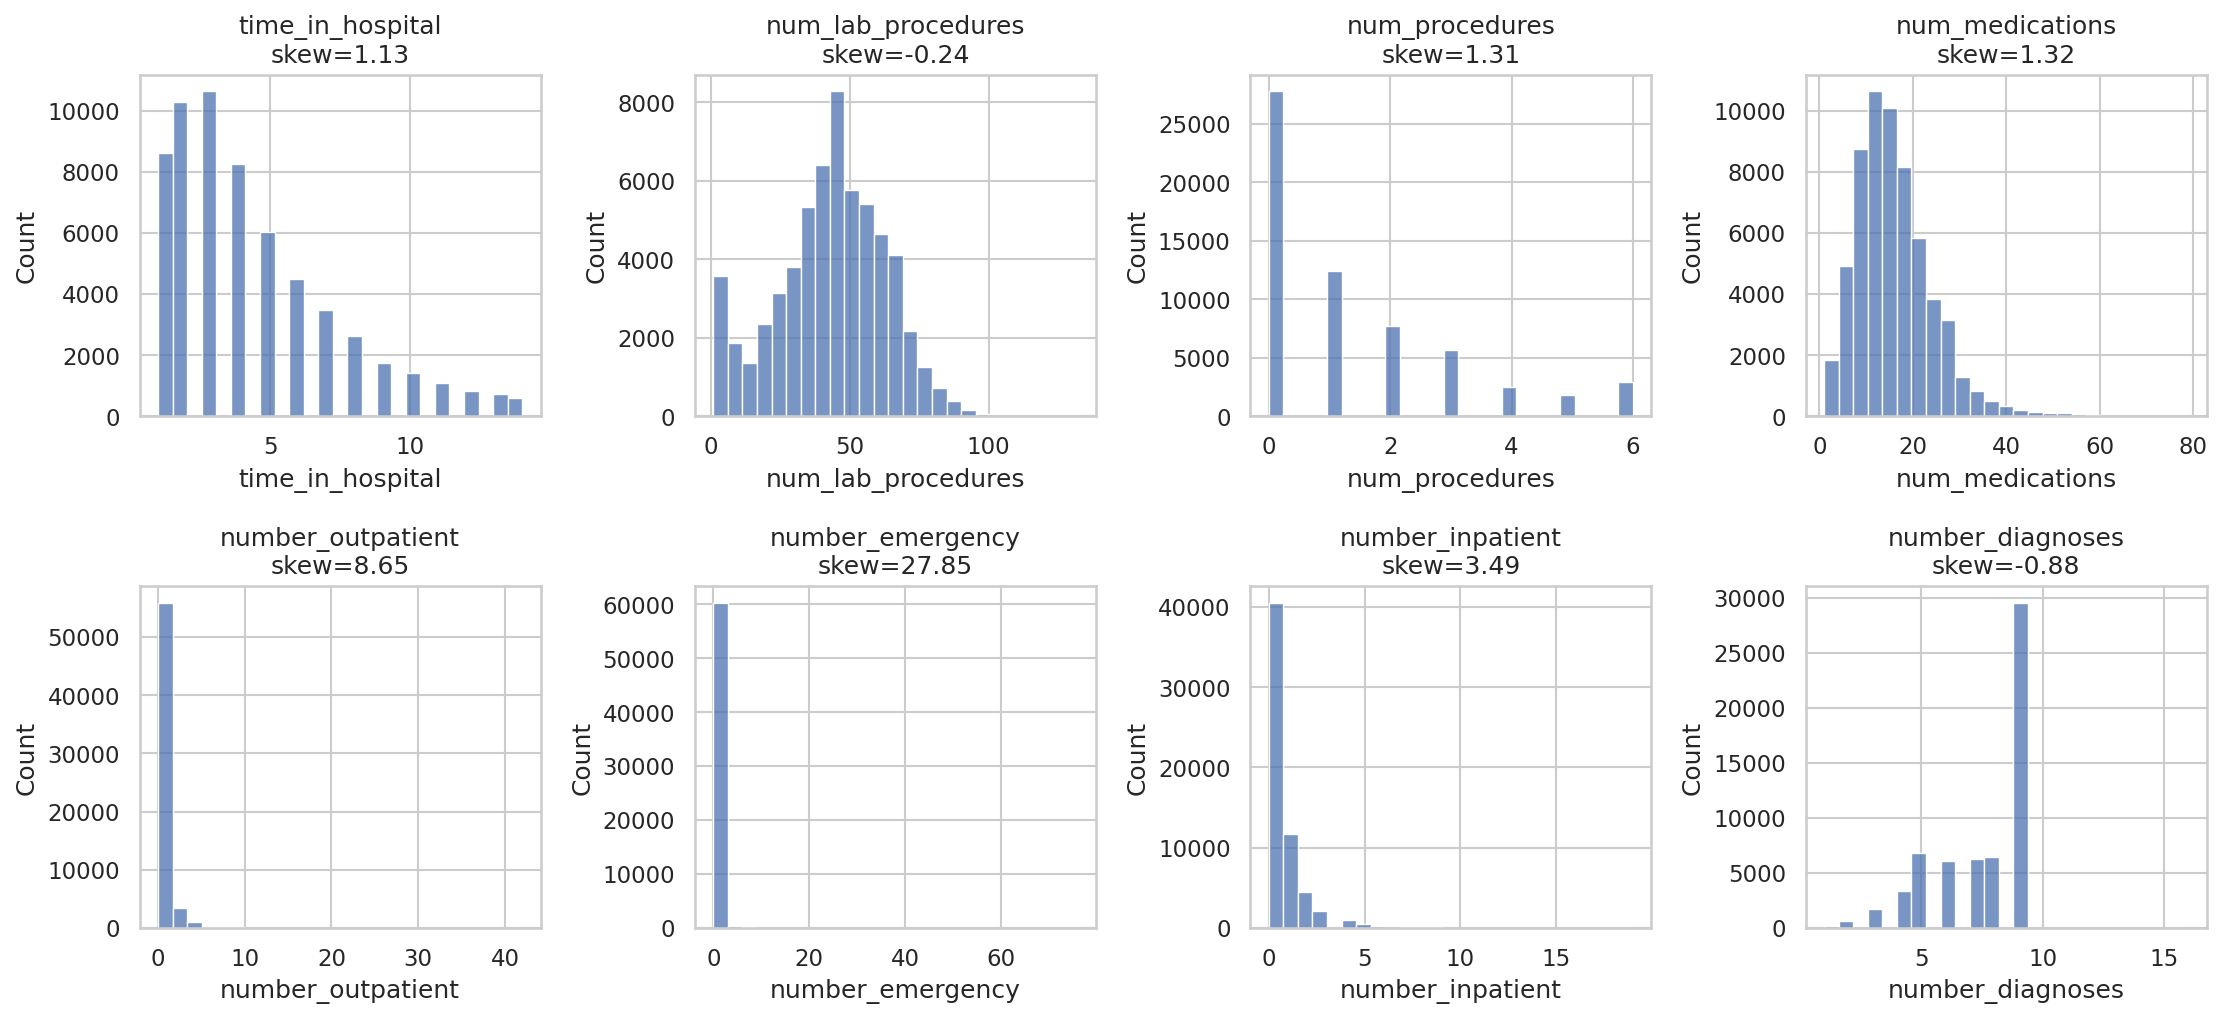

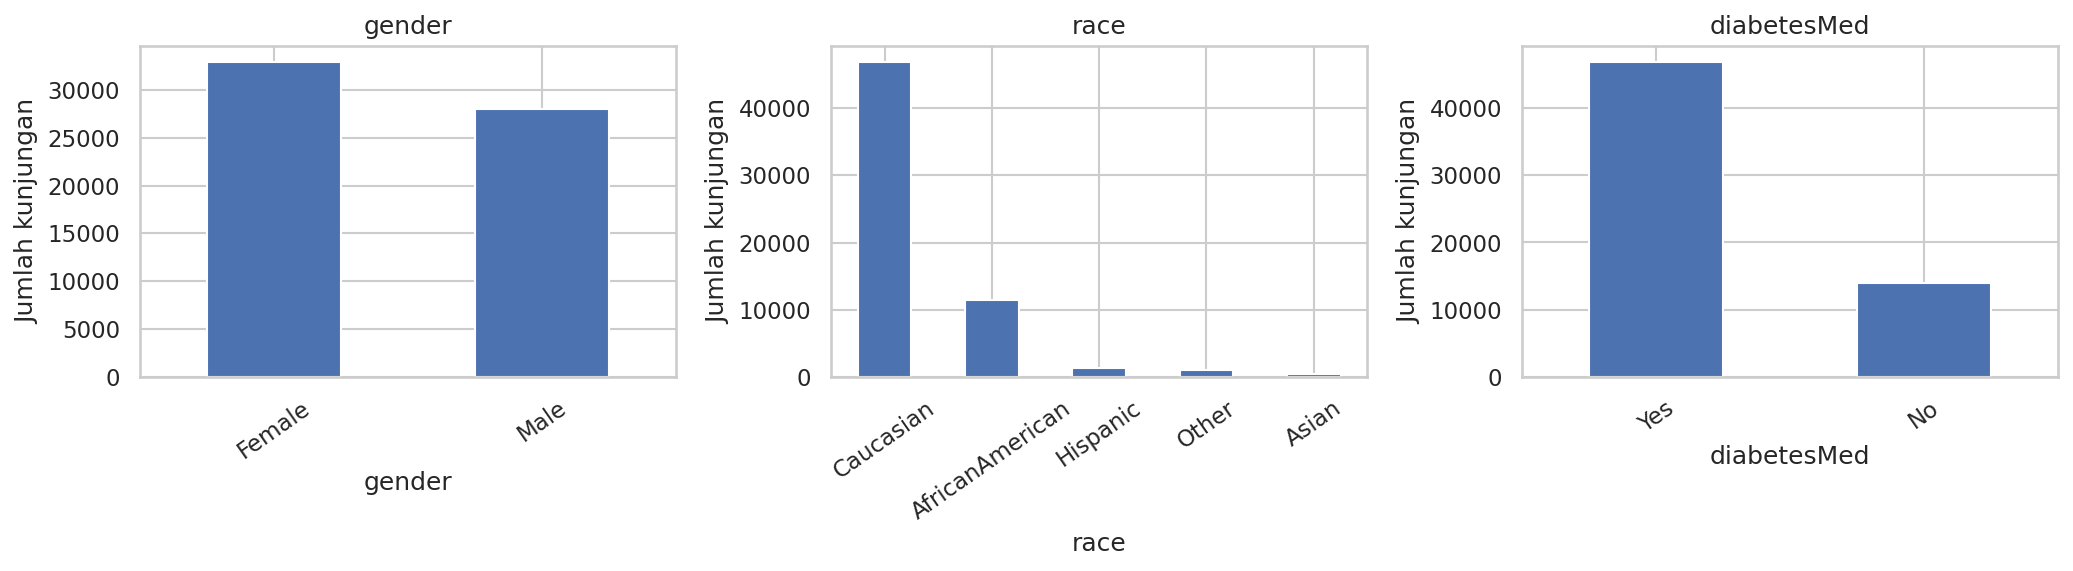

In [ ]:
display(Image(filename=str(OUT/'univariate_numeric.png')))
display(Image(filename=str(OUT/'univariate_categorical.png')))


**TULIS SENDIRI:** fitur mana skew kanan? Apakah terlihat lebih dari satu puncak? Jangan menyatakan multimodal hanya dari satu bin histogram; coba jumlah bin lain bila perlu. Jelaskan dampak pada scaling, outlier dan interpretasi.

## 4. Jawab tiga pertanyaan dengan angka dan visual

,n,positive,rate
age,,,
[0-10),93,3,0.032258
[10-20),413,23,0.055690
[20-30),981,137,0.139653
[30-40),2275,258,0.113407
[40-50),5870,630,0.107325
[50-60),10295,975,0.094706
[60-70),13349,1471,0.110196
[70-80),15594,1839,0.117930
[80-90),10317,1238,0.119996


,n,positive,rate
prior_admission_group,,,
0,40533,3416,0.084277
1,11682,1498,0.128231
2,4511,787,0.174462
3+,4152,1061,0.255539


,n,mean,median,std,q25,q75
target,,,,,,
0,54116,4.335409,4.0,2.972289,2.0,6.0
1,6762,4.771961,4.0,2.997913,3.0,6.0


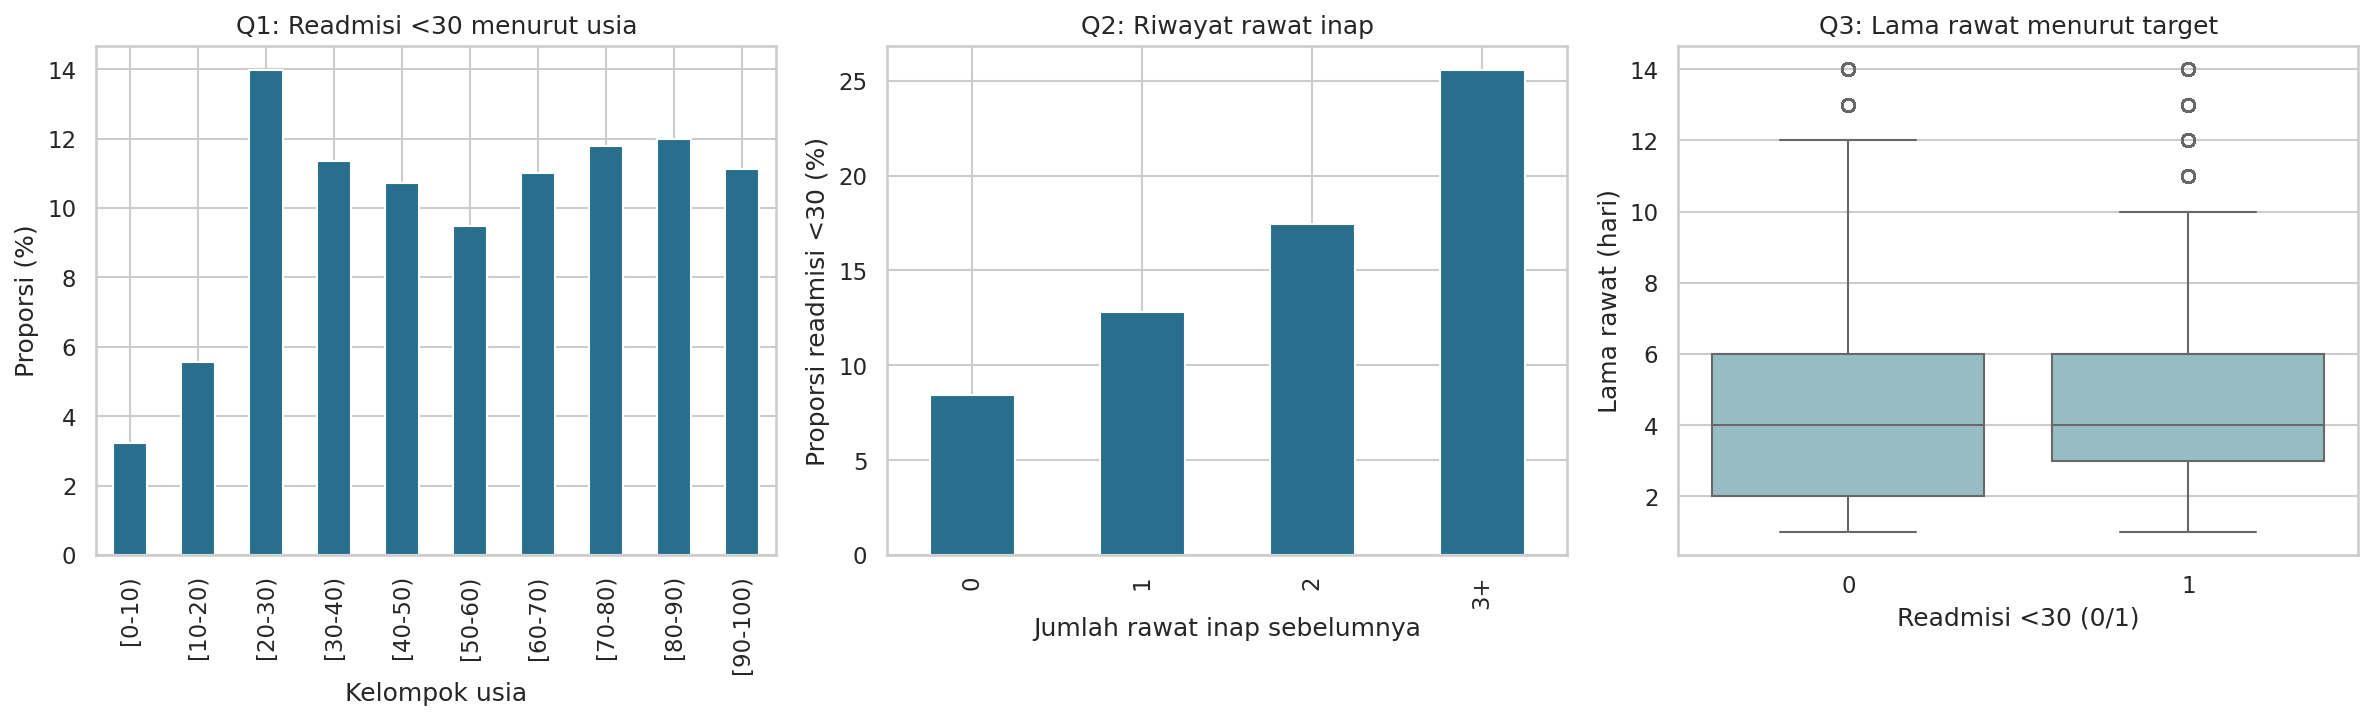

In [ ]:
display(q1);display(q2);display(q3)
display(Image(filename=str(OUT/'three_questions.png')))


**Hasil:**
- Q1: sebutkan kelompok, jumlah observasi, dan proporsi. Kelompok kecil lebih tidak stabil.
- Q2: jelaskan pola proporsi antar kelompok riwayat rawat inap; tidak menyatakan sebab-akibat.
- Q3: bandingkan median, IQR dan mean; apakah selisih cukup berarti secara praktis?

Unit tabel adalah kunjungan; kunjungan pasien yang sama berkorelasi. Tidak ada uji p-value independensi palsu untuk menjawab pertanyaan ini. Inferensi lanjutan membutuhkan bootstrap cluster pasien atau model yang memperhitungkan kelompok.


## 5. Bivariat dan multivariat

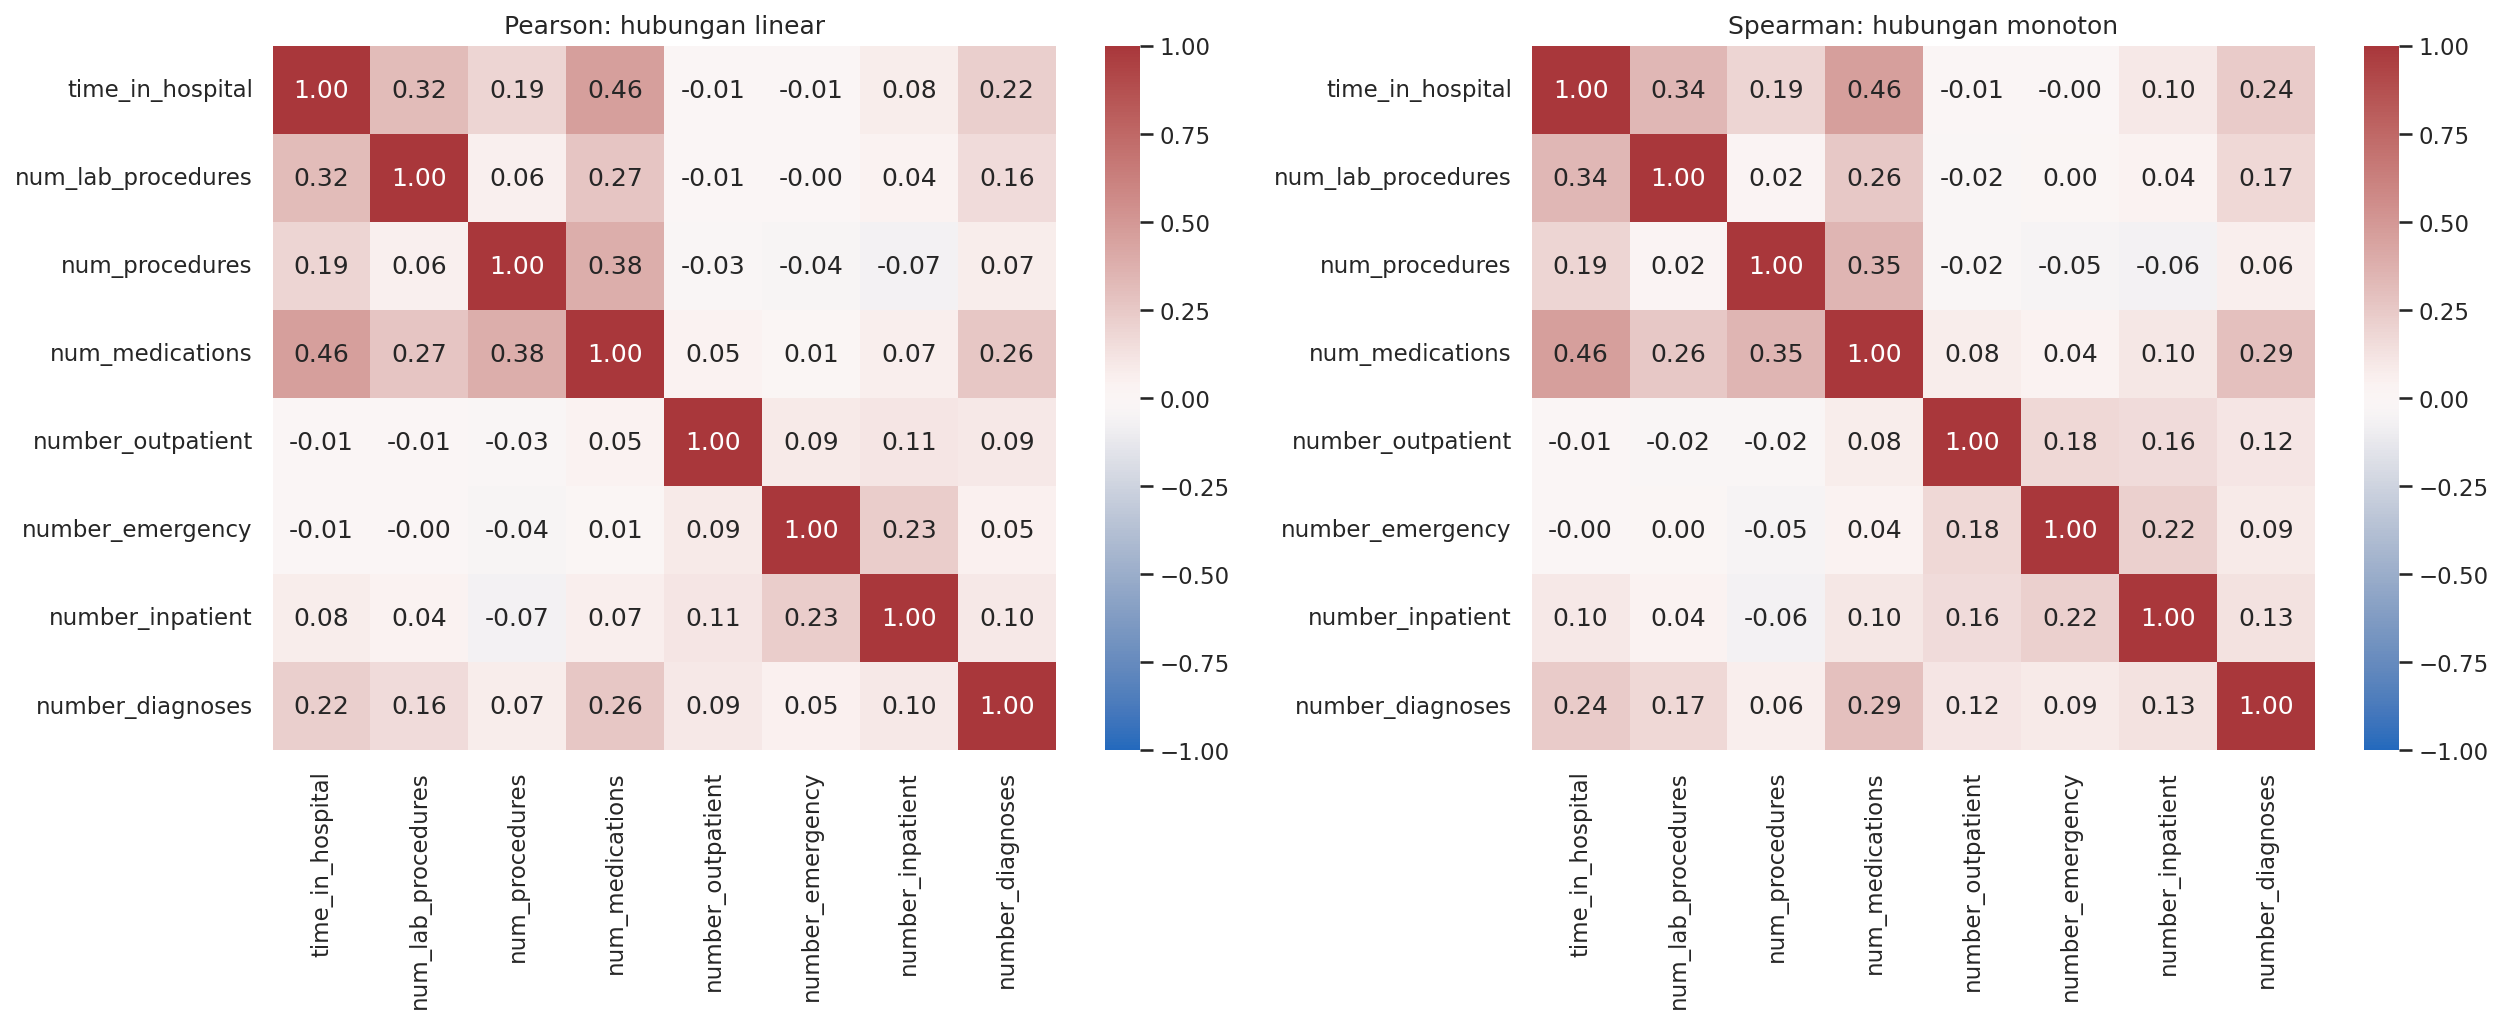

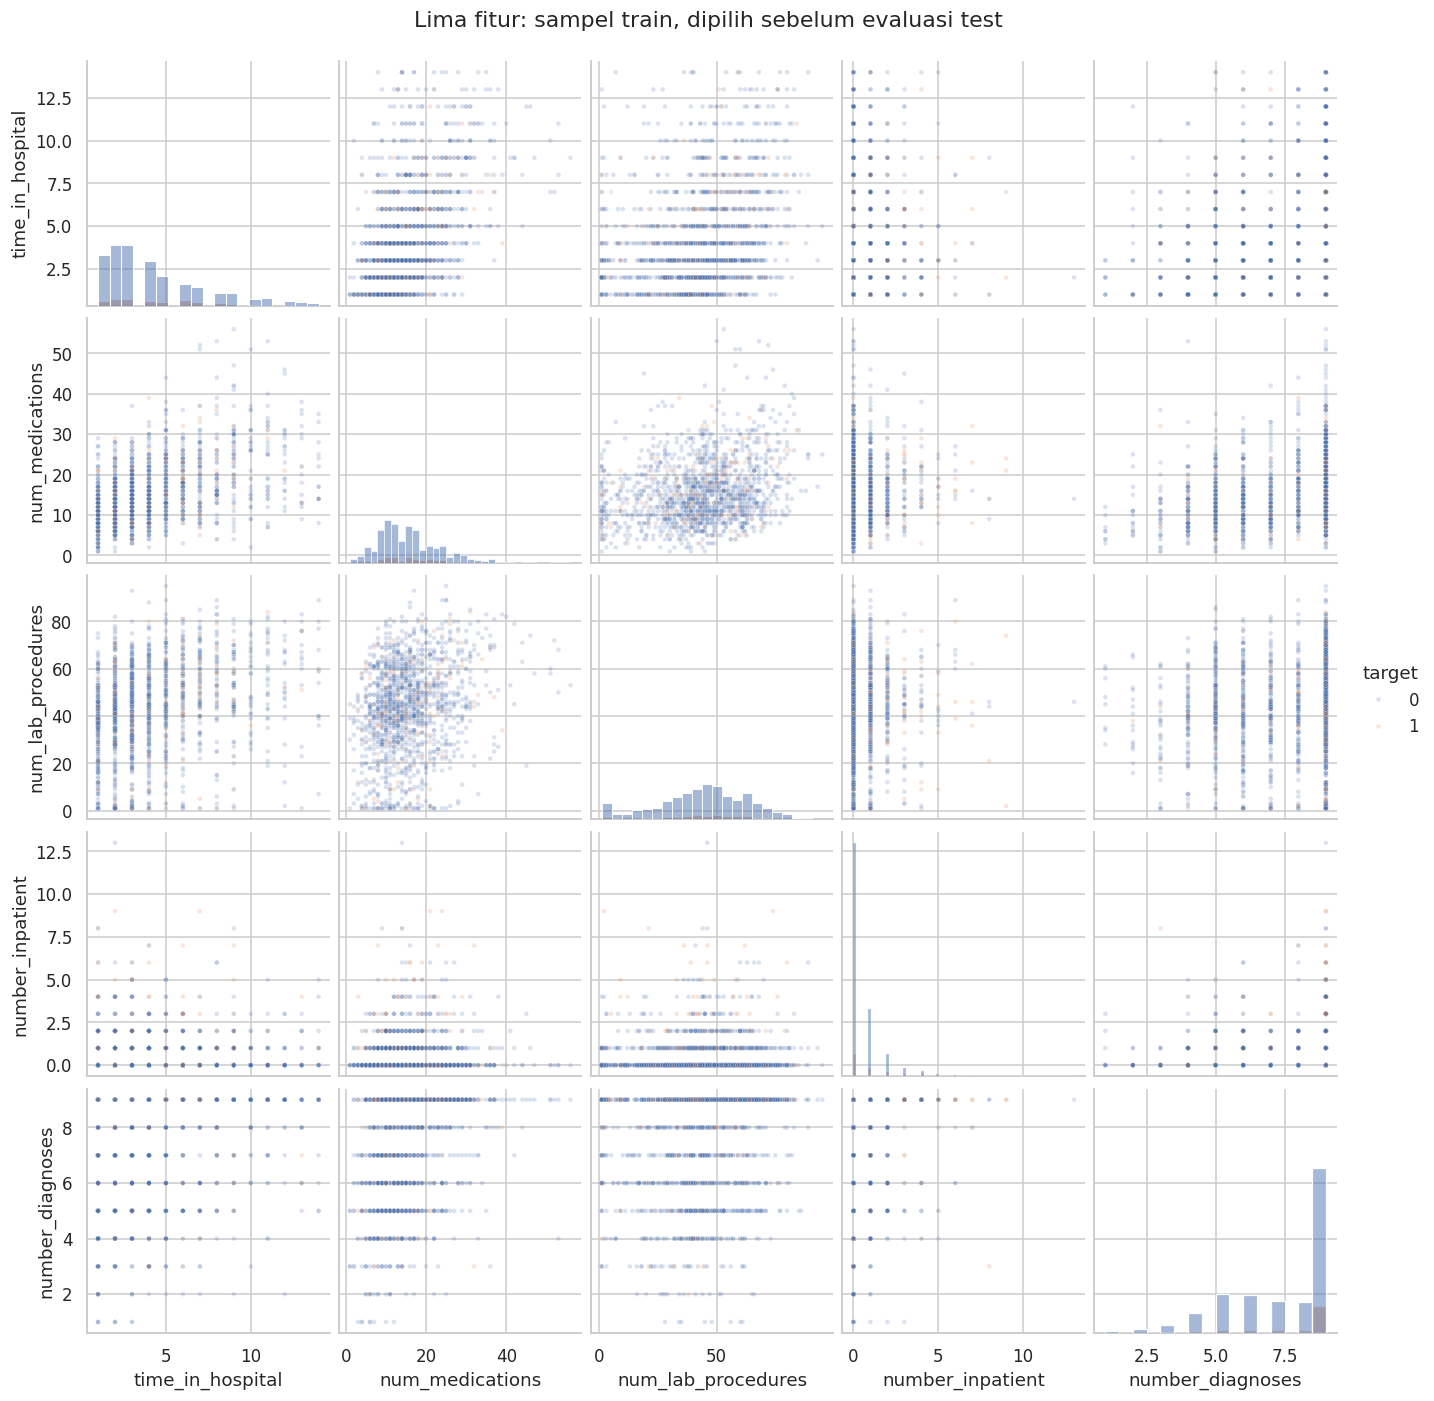

In [ ]:
display(Image(filename=str(OUT/'correlations.png')))
display(Image(filename=str(OUT/'pairplot.png')))


bandingkan Pearson dan Spearman. Pilih sesuai bentuk hubungan; ketidaknormalan saja bukan alasan otomatis membuang Pearson. Korelasi tinggi tidak otomatis berarti harus membuang fitur.

## 6. Dampak pembersihan terhadap distribusi/korelasi

,race,before_pct,after_pct
0,Caucasian,74.749499,77.001544
1,AfricanAmerican,18.762114,18.762114
2,Missing,2.252045,0.000000
3,Hispanic,2.033575,2.033575
4,Other,1.550642,1.550642
5,Asian,0.652124,0.652124


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,time_in_hospital,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,num_lab_procedures,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,num_procedures,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,num_medications,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,number_emergency,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,number_inpatient,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,number_diagnoses,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,Unnamed: 0,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,time_in_hospital,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,num_lab_procedures,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,num_procedures,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,num_medications,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,number_emergency,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,number_inpatient,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,number_diagnoses,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


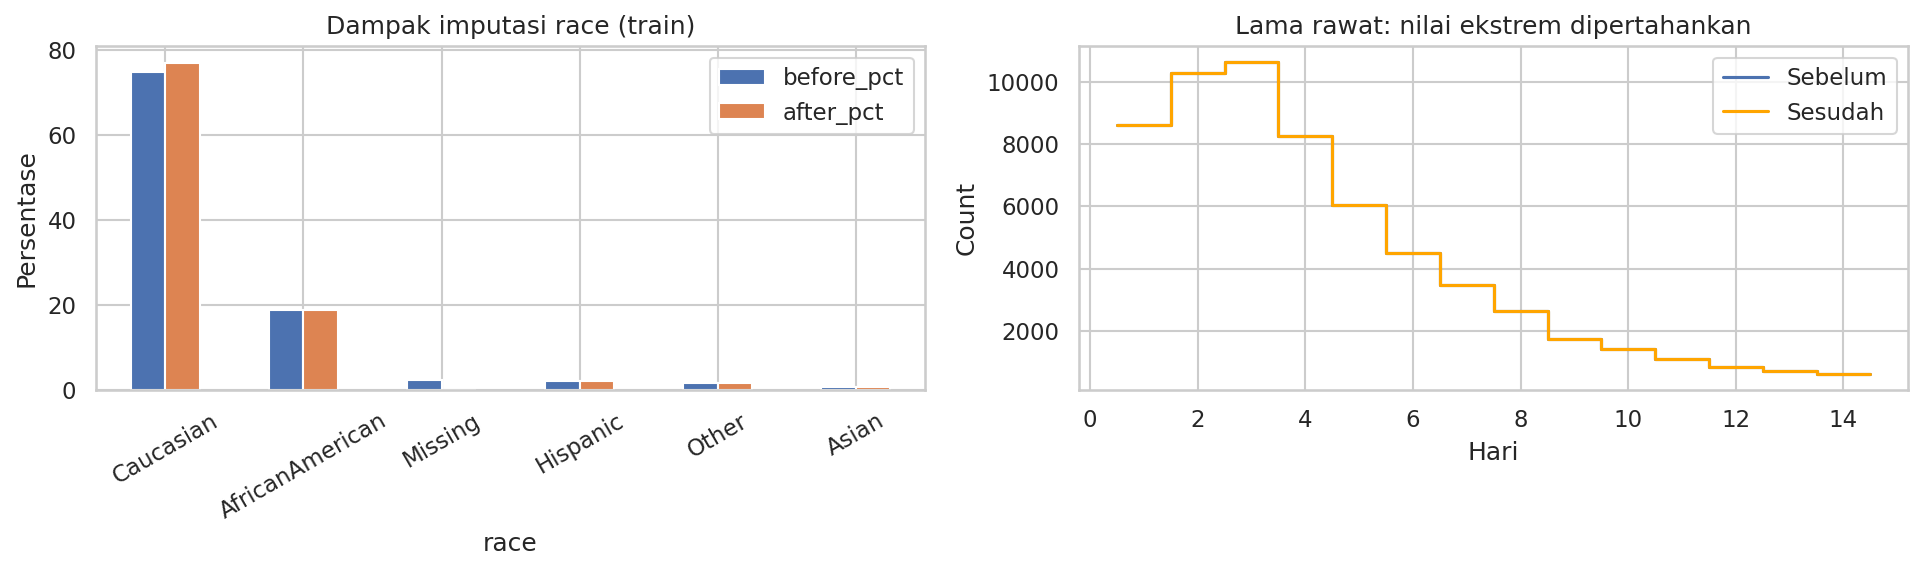

In [ ]:
display(pd.read_csv(OUT/'race_before_after.csv'))
display(pd.read_csv(OUT/'numeric_descriptive_delta.csv'))
display(pd.read_csv(OUT/'correlation_delta.csv'))
display(Image(filename=str(OUT/'before_after.png')))


pada data ini nilai numerik dapat tidak berubah karena outlier dipertahankan. Selisih nol tetap hasil yang valid. Scaling hanya pada matriks model; tabel EDA tetap unit asli. Bandingkan perubahan distribusi race akibat imputasi.

## 7. Normalitas dan multikolinearitas

,feature,n,W,p,skewness
0,time_in_hospital,5000,0.884373,1.100781e-51,1.134415
1,num_lab_procedures,5000,0.983644,1.285070e-23,-0.235244
2,num_procedures,5000,0.787435,9.575811e-63,1.314226
3,num_medications,5000,0.908652,1.063609e-47,1.317180
4,number_outpatient,5000,0.276926,2.500831e-88,8.650394
5,number_emergency,5000,0.187320,5.287398e-91,27.849659
6,number_inpatient,5000,0.329802,1.303061e-86,3.486339
7,number_diagnoses,5000,0.832295,2.620625e-58,-0.882590


,feature,VIF
0,time_in_hospital,1.363158
1,num_lab_procedures,1.147583
2,num_procedures,1.192908
3,num_medications,1.529443
4,number_outpatient,1.027624
5,number_emergency,1.063149
6,number_inpatient,1.086529
7,number_diagnoses,1.109744


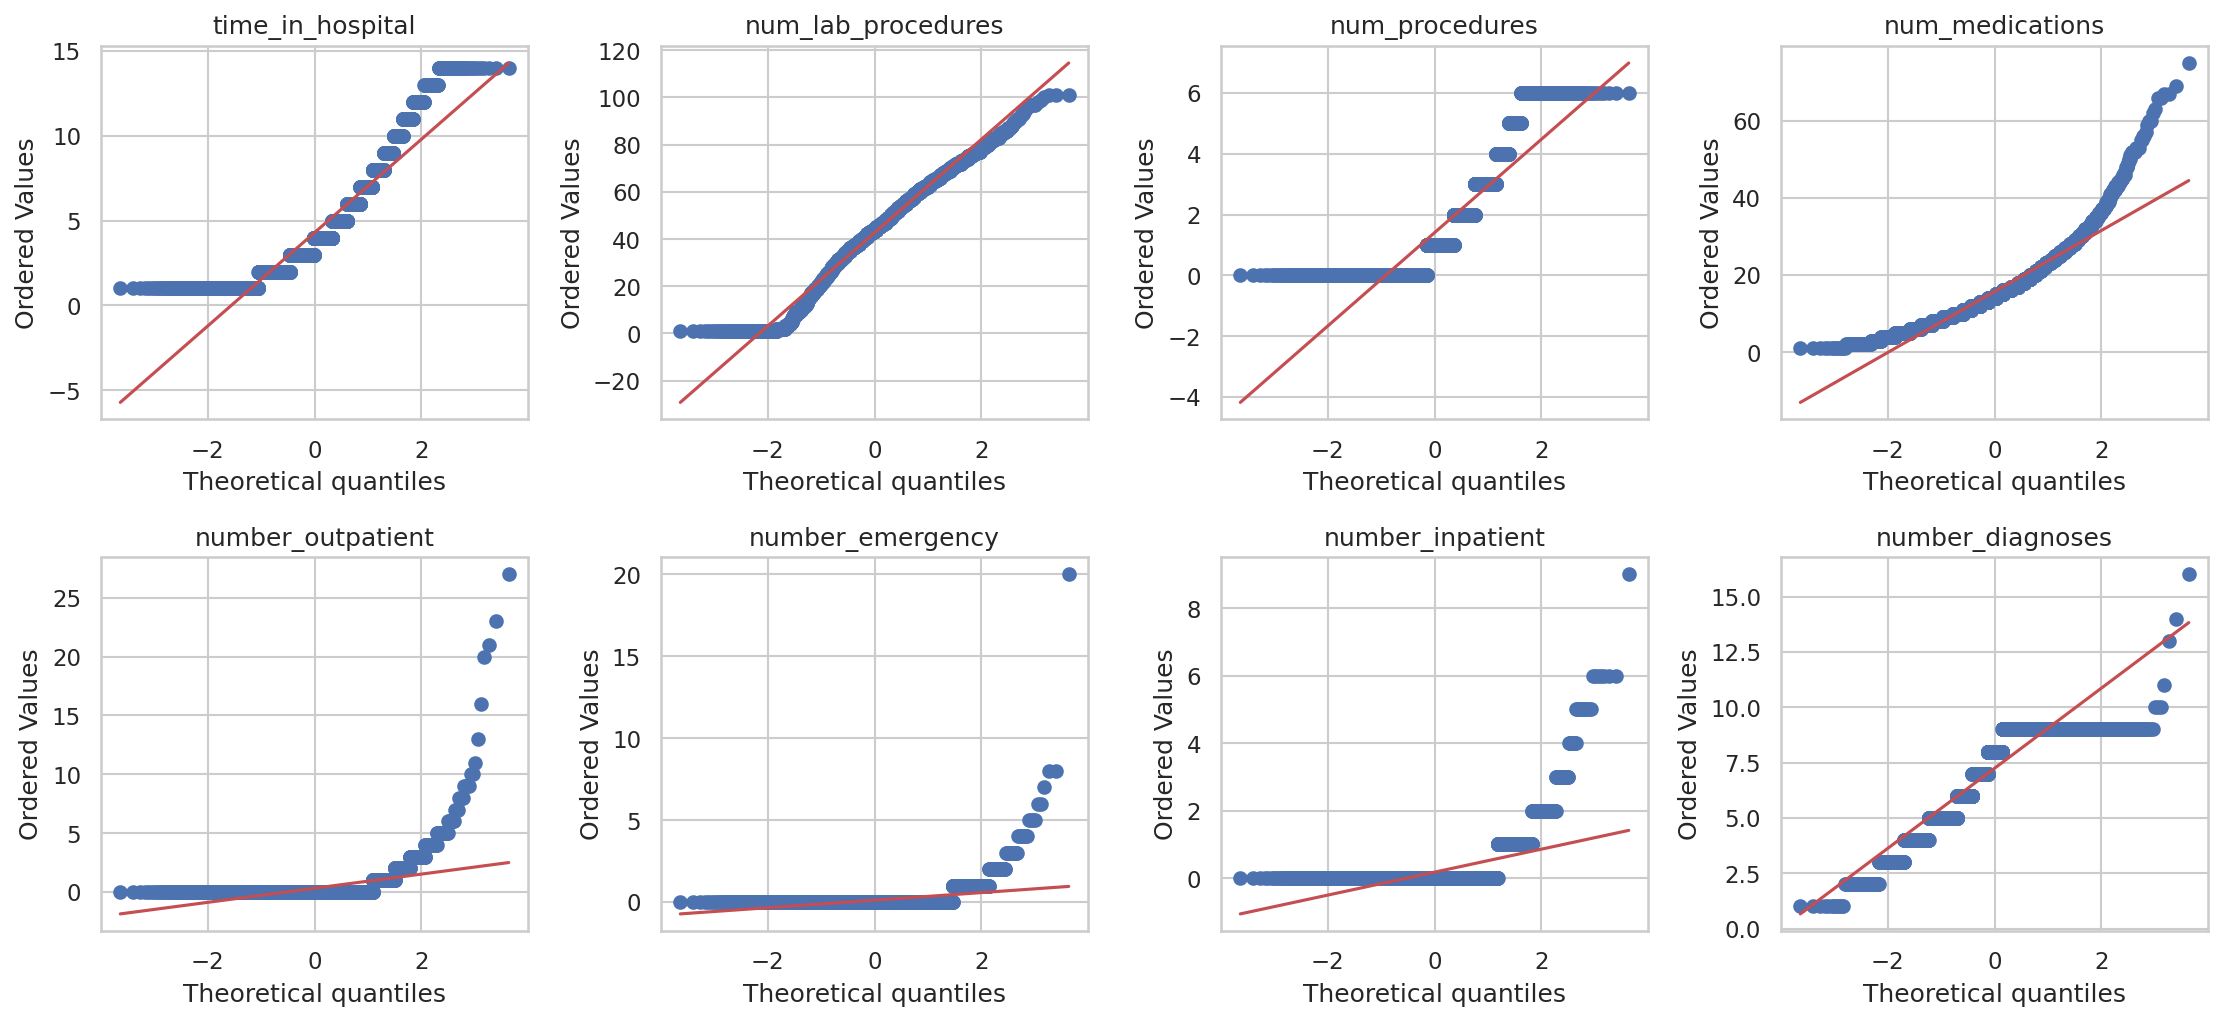

In [ ]:
display(pd.read_csv(OUT/'normality.csv'));display(vif)
display(Image(filename=str(OUT/'qqplots.png')))


interpretasikan statistik dan Q-Q plot bersama. Sampel besar membuat uji sensitif. VIF >5/10 hanya pedoman; pertimbangkan tujuan dan jenis model. Pemeriksaan ini bukan alasan mengubah model setelah test dibuka.

## 8. Ringkasan satu halaman

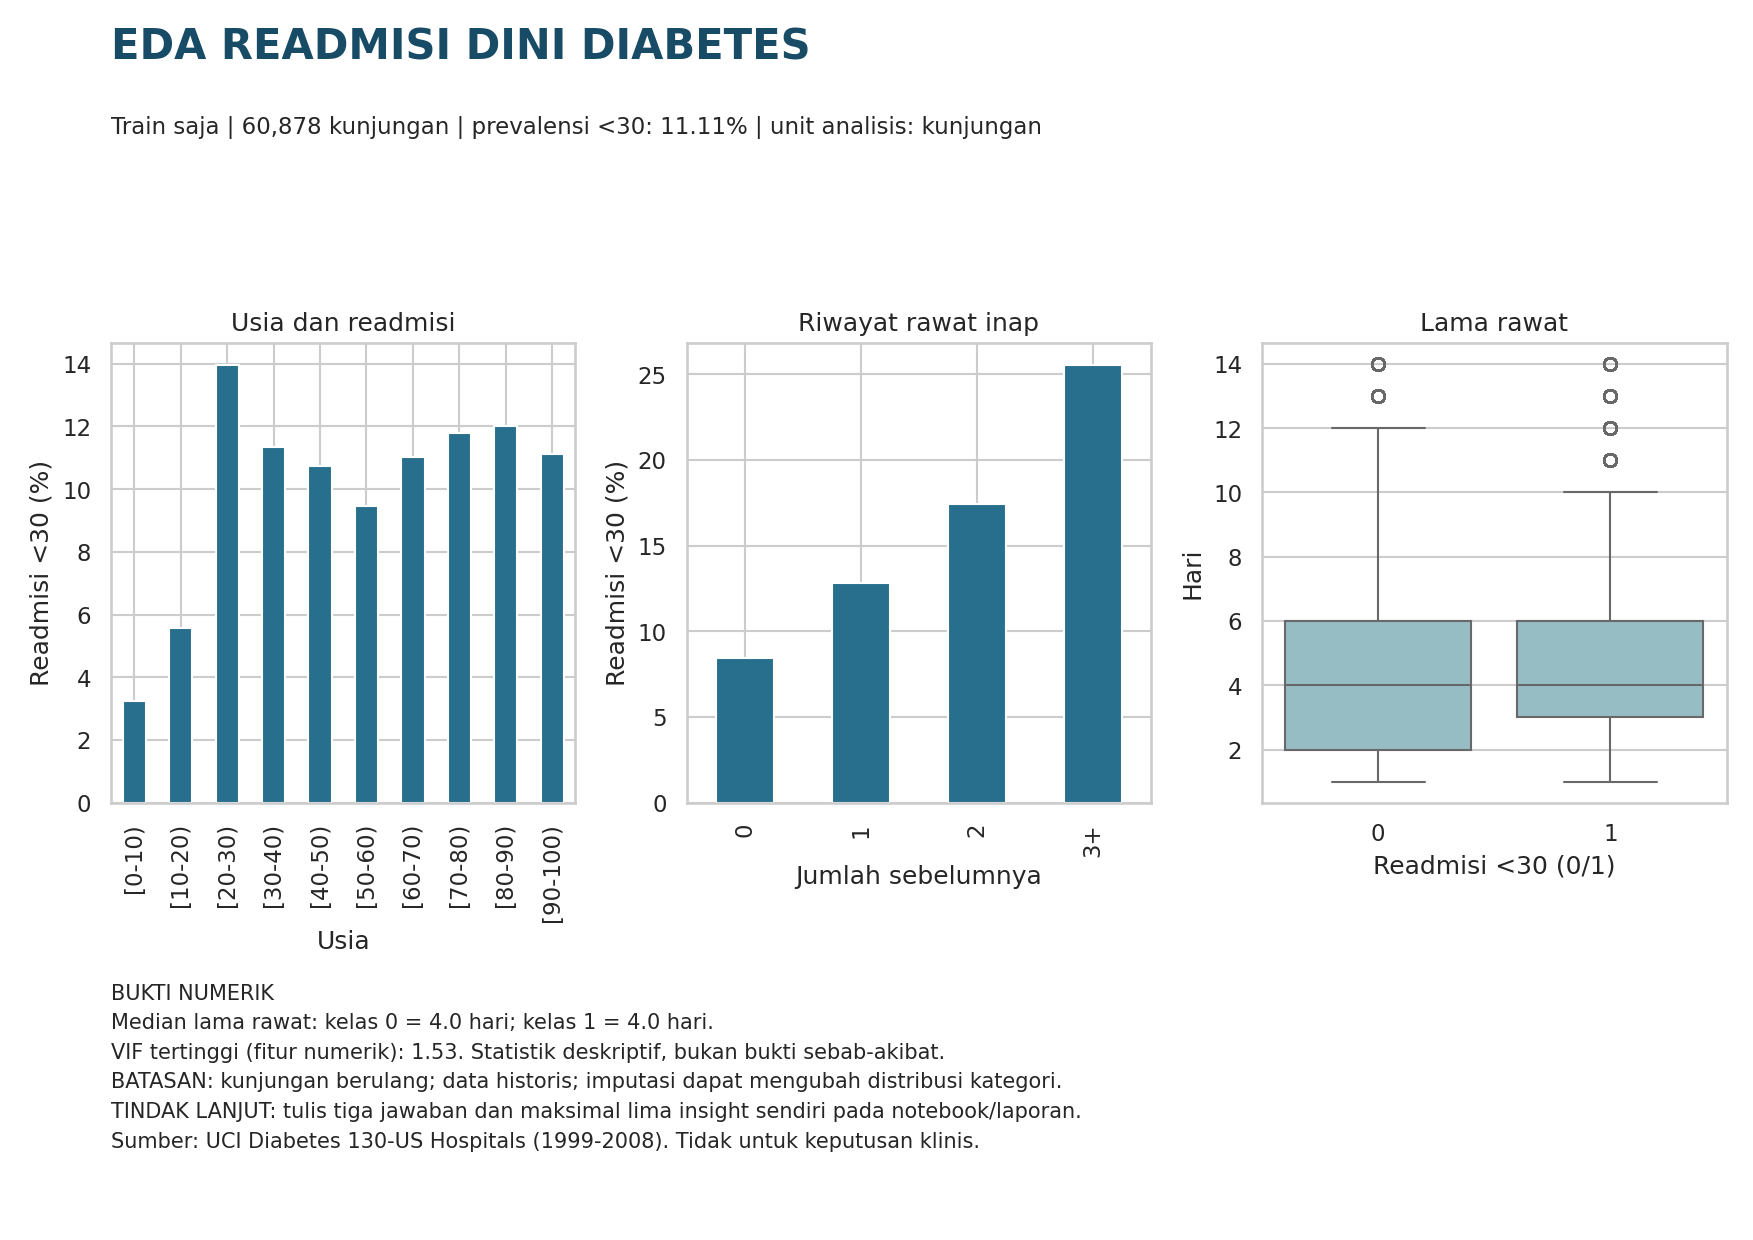

PDF poster: /content/drive/MyDrive/MP2_MP4_Diabetes/mp4/ringkasan_EDA_1_halaman.pdf


In [ ]:
display(Image(filename=str(OUT/'ringkasan_EDA_1_halaman.png')))
print('PDF poster:', OUT/'ringkasan_EDA_1_halaman.pdf')
